# Notebook 09: Univariate and PCA baselines

The manuscript claims that NMF recovers a distributed sex signal that univariate testing misses. That claim is currently asserted from the literature rather than demonstrated on these data. This notebook demonstrates it — or fails to, which would be equally worth knowing.

Two baselines are run on the *same* feature matrix that fed the NMF:

1. **Mass-univariate.** Every one of the 350 (category × channel × band) features is tested against sex individually, with Benjamini–Hochberg FDR across all 350. This is the analysis the manuscript argues is underpowered for distributed, sign-varying structure.

2. **Cluster-based permutation.** The standard EEG remedy for mass-univariate testing: neighbouring features that exceed a threshold with the *same sign* are pooled into clusters, and the largest cluster mass is compared against a permutation null. This is a fairer adversary than naive univariate testing, because it is explicitly designed to recover spatially extended effects. It should still struggle with sign-varying structure, since a cluster requires a consistent direction.

3. **PCA embedding.** PCA to the same number of components as the NMF, pushed through the identical omnibus permutation test. This isolates what NMF's non-negativity and parts-based representation contribute over a generic linear embedding.

**Inputs:** `outputs/feature_matrix.csv`, `outputs/metadata.csv`, `outputs/nmf_W.csv`, `outputs/omnibus_results.csv`

**Outputs:** `outputs/baseline_univariate.csv`, `outputs/baseline_clusters.csv`, `outputs/baseline_pca_omnibus.csv`, `outputs/baseline_pca_posthoc.csv`, `outputs/baseline_comparison.csv`, `outputs/baselines.png`

## Setup

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from scipy import stats
from scipy.sparse import lil_matrix, csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt
import time
import warnings
warnings.filterwarnings("ignore")

PROJECT_ROOT = Path(".").resolve().parent
OUTPUT_DIR = PROJECT_ROOT / "outputs"

FREQ_BANDS = ["Theta", "Alpha", "BetaL", "BetaH", "Gamma"]
CHANNELS = ["AF3", "F7", "F3", "FC5", "T7", "P7", "O1",
            "O2", "P8", "T8", "FC6", "F4", "F8", "AF4"]

N_PERMUTATIONS = 5000
FDR_ALPHA = 0.05
RANDOM_SEED = 42
N_PCA_COMPONENTS = 5

CLUSTER_FORMING_P = 0.05      # threshold for a feature to enter a cluster
CROSS_CATEGORY_ADJACENCY = False   # clusters stay within a task category by default

SEX_COL = "Gender"
SEX_ORDER = ["F", "M"]        # positive effect = higher in females

report = []
def log(msg=""):
    print(msg); report.append(str(msg))

## Load data

In [2]:
X = pd.read_csv(OUTPUT_DIR / "feature_matrix.csv", index_col="participant_id")
metadata = pd.read_csv(OUTPUT_DIR / "metadata.csv").set_index("participant_id").reindex(X.index)
W_nmf = pd.read_csv(OUTPUT_DIR / "nmf_W.csv", index_col="participant_id")
omnibus_orig = pd.read_csv(OUTPUT_DIR / "omnibus_results.csv")

assert (X.index == metadata.index).all()
sex = metadata[SEX_COL]
is_female = (sex == SEX_ORDER[0]).values
log(f"Feature matrix: {X.shape}")
log(f"Sex: {dict(sex.value_counts())}")

def parse_feature(name):
    cat, pow_part = name.split("__", 1)
    _, ch, band = pow_part.split(".")
    return cat, ch, band

features = list(X.columns)
parsed = pd.DataFrame([parse_feature(f) for f in features],
                      columns=["category", "channel", "band"], index=features)
categories = sorted(parsed["category"].unique())
log(f"Categories: {categories}")

nmf_sex = omnibus_orig[omnibus_orig["variable"] == SEX_COL].iloc[0]
log(f"\nNMF omnibus for sex (for reference): stat = {nmf_sex['observed_stat']:.4f}, "
    f"p_perm = {nmf_sex['p_perm']:.4f}, p_fdr = {nmf_sex['p_fdr']:.4f}")

Feature matrix: (86, 350)
Sex: {'M': 44, 'F': 42}
Categories: ['frontal', 'frontal_central', 'occipital', 'parietal', 'temporal']

NMF omnibus for sex (for reference): stat = 0.2742, p_perm = 0.0002, p_fdr = 0.0034


## Baseline 1 — mass-univariate testing

Every feature tested separately against sex with a Mann–Whitney U test, then Benjamini–Hochberg FDR across all 350. Effect size is the rank-biserial correlation with a fixed group order, so positive means higher in females throughout.

The quantity of interest is not just how many features survive, but the **sign balance** among the features with the largest raw effects. A distributed, sign-varying signal should show substantial effect sizes in both directions, which is precisely what defeats both univariate averaging and cluster-based pooling.

In [3]:
def rank_biserial(values, female_mask):
    f = values[female_mask]; m = values[~female_mask]
    u, p = stats.mannwhitneyu(f, m, alternative="two-sided")
    return 2.0 * u / (len(f) * len(m)) - 1.0, p

rows = []
Xv = X.values
for j, feat in enumerate(features):
    r, p = rank_biserial(Xv[:, j], is_female)
    rows.append({"feature": feat, "category": parsed.loc[feat, "category"],
                 "channel": parsed.loc[feat, "channel"], "band": parsed.loc[feat, "band"],
                 "rank_biserial": r, "p_raw": p})
uni = pd.DataFrame(rows)
reject, p_fdr, _, _ = multipletests(uni["p_raw"], alpha=FDR_ALPHA, method="fdr_bh")
uni["p_fdr"] = p_fdr
uni["significant_fdr"] = reject
uni = uni.sort_values("p_raw").reset_index(drop=True)
uni.to_csv(OUTPUT_DIR / "baseline_univariate.csv", index=False)

n_nominal = int((uni["p_raw"] < 0.05).sum())
n_fdr = int(uni["significant_fdr"].sum())
log(f"Features tested:                    {len(uni)}")
log(f"Nominally significant (p < 0.05):   {n_nominal}  "
    f"(expected by chance: {0.05*len(uni):.0f})")
log(f"Surviving FDR correction:           {n_fdr}")

log("\nTop 15 features by raw p-value:")
log(uni.head(15)[["category", "channel", "band", "rank_biserial", "p_raw", "p_fdr",
                  "significant_fdr"]].round(4).to_string(index=False))

top100 = uni.head(100)
log(f"\nSign balance among the 100 strongest features:")
log(f"  higher in females: {int((top100['rank_biserial'] > 0).sum())}")
log(f"  higher in males:   {int((top100['rank_biserial'] < 0).sum())}")
log(f"  mean signed effect:     {top100['rank_biserial'].mean():+.4f}")
log(f"  mean |effect|:          {top100['rank_biserial'].abs().mean():.4f}")
log("\nA mean signed effect near zero alongside a substantial mean absolute effect is the")
log("signature of sign-varying structure: real per-feature differences that cancel on averaging.")

Features tested:                    350
Nominally significant (p < 0.05):   36  (expected by chance: 18)
Surviving FDR correction:           0

Top 15 features by raw p-value:
       category channel  band  rank_biserial  p_raw  p_fdr  significant_fdr
        frontal     AF3 Theta         0.4535 0.0003 0.0540            False
       temporal     AF3 Theta         0.4286 0.0006 0.0540            False
frontal_central      F7 Theta         0.4199 0.0008 0.0540            False
       parietal     AF3 Theta         0.4123 0.0010 0.0540            False
       parietal      F8 Theta         0.4123 0.0010 0.0540            False
       temporal      F7 Theta         0.4069 0.0012 0.0540            False
       parietal      F7 Theta         0.4058 0.0012 0.0540            False
       parietal     AF4 Theta         0.4004 0.0014 0.0540            False
frontal_central     AF3 Gamma         0.3983 0.0015 0.0540            False
frontal_central     AF4 Theta         0.3972 0.0015 0.0540      

## Baseline 2 — cluster-based permutation test

Adjacency is defined over the EPOC montage: two features are neighbours if they share a channel and sit in adjacent frequency bands, or share a band and sit at spatially neighbouring electrodes. By default clusters do not span task categories, since the five categories are aggregates of different tasks rather than points on a continuous manifold.

The cluster-forming threshold is the two-sided *t* critical value at p = 0.05. Clusters must be sign-consistent. The test statistic is the maximum cluster mass (summed *t*), and the null is built by permuting sex labels, refitting, and recording the maximum cluster mass each time — the standard Maris–Oostenveld procedure, which controls the family-wise error rate at the cluster level.

In [4]:
CHANNEL_NEIGHBOURS = {
    "AF3": ["F7", "F3", "AF4"],
    "F7":  ["AF3", "F3", "FC5", "T7"],
    "F3":  ["AF3", "F7", "FC5", "F4"],
    "FC5": ["F7", "F3", "T7"],
    "T7":  ["F7", "FC5", "P7"],
    "P7":  ["T7", "O1"],
    "O1":  ["P7", "O2"],
    "O2":  ["O1", "P8"],
    "P8":  ["O2", "T8"],
    "T8":  ["P8", "FC6", "F8"],
    "FC6": ["T8", "F8", "F4"],
    "F8":  ["FC6", "F4", "AF4", "T8"],
    "F4":  ["F3", "FC6", "F8", "AF4"],
    "AF4": ["AF3", "F4", "F8"],
}
# Symmetry check — an asymmetric adjacency map is a silent source of wrong clusters
for a, nbrs in CHANNEL_NEIGHBOURS.items():
    for b in nbrs:
        assert a in CHANNEL_NEIGHBOURS[b], f"Adjacency not symmetric: {a}-{b}"
log("Channel adjacency map is symmetric.")

fidx = {f: i for i, f in enumerate(features)}
n_feat = len(features)
A = lil_matrix((n_feat, n_feat), dtype=bool)

for f in features:
    cat, ch, band = parse_feature(f)
    i = fidx[f]
    for ch2 in CHANNEL_NEIGHBOURS[ch]:
        g = f"{cat}__POW.{ch2}.{band}"
        if g in fidx:
            A[i, fidx[g]] = True
    bi = FREQ_BANDS.index(band)
    for bj in (bi - 1, bi + 1):
        if 0 <= bj < len(FREQ_BANDS):
            g = f"{cat}__POW.{ch}.{FREQ_BANDS[bj]}"
            if g in fidx:
                A[i, fidx[g]] = True
    if CROSS_CATEGORY_ADJACENCY:
        for cat2 in categories:
            if cat2 == cat:
                continue
            g = f"{cat2}__POW.{ch}.{band}"
            if g in fidx:
                A[i, fidx[g]] = True

A = csr_matrix(A)
log(f"Adjacency graph: {n_feat} nodes, {int(A.nnz / 2)} undirected edges "
    f"(cross-category = {CROSS_CATEGORY_ADJACENCY})")

Channel adjacency map is symmetric.
Adjacency graph: 350 nodes, 805 undirected edges (cross-category = False)


In [5]:
def welch_t(Xv, female_mask):
    a, b = Xv[female_mask], Xv[~female_mask]
    na, nb = a.shape[0], b.shape[0]
    va, vb = a.var(axis=0, ddof=1), b.var(axis=0, ddof=1)
    se = np.sqrt(va / na + vb / nb)
    se = np.where(se == 0, np.inf, se)
    return (a.mean(axis=0) - b.mean(axis=0)) / se

df_approx = len(X) - 2
T_THRESH = stats.t.ppf(1 - CLUSTER_FORMING_P / 2, df_approx)
log(f"Cluster-forming threshold: |t| > {T_THRESH:.3f} (two-sided p = {CLUSTER_FORMING_P}, df ≈ {df_approx})")

def find_clusters(t, return_members=False):
    """Sign-consistent connected clusters of suprathreshold features. Returns list of (mass, sign, members)."""
    out = []
    for sign in (1, -1):
        mask = (t * sign) > T_THRESH
        if not mask.any():
            continue
        idx_sel = np.where(mask)[0]
        sub = A[idx_sel][:, idx_sel]
        ncomp, labels = connected_components(sub, directed=False)
        vals = t[idx_sel] * sign
        for c in range(ncomp):
            members = idx_sel[labels == c]
            mass = float(vals[labels == c].sum())
            out.append((mass, sign, members if return_members else None))
    return out

t_obs = welch_t(Xv, is_female)
obs_clusters = find_clusters(t_obs, return_members=True)
obs_max = max([m for m, _, _ in obs_clusters], default=0.0)
log(f"\nObserved clusters: {len(obs_clusters)}; maximum cluster mass = {obs_max:.3f}")

rng = np.random.default_rng(RANDOM_SEED)
null_max = np.zeros(N_PERMUTATIONS)
perm_mask = is_female.copy()
t0 = time.time()
for i in range(N_PERMUTATIONS):
    rng.shuffle(perm_mask)
    t_perm = welch_t(Xv, perm_mask)
    cl = find_clusters(t_perm)
    null_max[i] = max([m for m, _, _ in cl], default=0.0)
log(f"Permutation null built in {time.time() - t0:.0f}s")

cluster_rows = []
for mass, sign, members in sorted(obs_clusters, key=lambda c: -c[0]):
    p_clust = (np.sum(null_max >= mass) + 1) / (N_PERMUTATIONS + 1)
    feats = [features[m] for m in members]
    cluster_rows.append({
        "cluster_mass": mass,
        "direction": "higher in females" if sign > 0 else "higher in males",
        "n_features": len(members),
        "p_cluster": p_clust,
        "categories": ",".join(sorted({parse_feature(f)[0] for f in feats})),
        "channels": ",".join(sorted({parse_feature(f)[1] for f in feats})),
        "bands": ",".join(sorted({parse_feature(f)[2] for f in feats})),
    })
cluster_df = pd.DataFrame(cluster_rows)
cluster_df.to_csv(OUTPUT_DIR / "baseline_clusters.csv", index=False)

if len(cluster_df):
    log("\nObserved clusters (sorted by mass):")
    log(cluster_df.head(12).round(4).to_string(index=False))
    n_sig_clusters = int((cluster_df["p_cluster"] < 0.05).sum())
    log(f"\nClusters significant at p < 0.05: {n_sig_clusters}")
else:
    log("\nNo suprathreshold clusters formed at all.")
    n_sig_clusters = 0

Cluster-forming threshold: |t| > 1.989 (two-sided p = 0.05, df ≈ 84)

Observed clusters: 9; maximum cluster mass = 17.406
Permutation null built in 3s

Observed clusters (sorted by mass):
 cluster_mass         direction  n_features  p_cluster      categories      channels       bands
      17.4059 higher in females           6     0.1930        temporal AF3,AF4,F7,F8 Alpha,Theta
      15.7864 higher in females           6     0.2072        parietal AF3,AF4,F7,F8 Alpha,Theta
      15.5797 higher in females           6     0.2098 frontal_central AF3,AF4,F7,F8 Alpha,Theta
      13.9771 higher in females           5     0.2310         frontal AF3,AF4,F7,F8 Alpha,Theta
       9.9154 higher in females           4     0.3125 frontal_central    AF3,AF4,F7 BetaH,Gamma
       9.1328 higher in females           4     0.3323 frontal_central         P8,T8 BetaH,Gamma
       4.0770 higher in females           2     0.6147 frontal_central            P7 BetaH,Gamma
       2.5067   higher in males     

## Baseline 3 — PCA embedding through the same omnibus test

PCA is fitted to the same feature matrix with the same number of components, and the resulting embedding is pushed through the identical omnibus permutation procedure over all 17 metadata variables, so that the FDR family matches.

PCA components are unconstrained in sign, so unlike NMF they can represent contrasts directly. If PCA recovers the sex signal as easily as NMF, the non-negativity constraint is doing less work than the manuscript implies, and the Methods framing should be softened accordingly.

In [6]:
VAR_TYPES = {
    "Age": "continuous", "Gender": "binary",
    "Residential Area (Urban/Rural)": "binary", "From City": "binary",
    "Single/NotSingle": "binary", "Education": "multi", "Field of Study": "multi",
    "Occupation": "multi", "# of LanguagesSpeak": "continuous", "UsedToDoSport": "binary",
    "NowDoingSports_aWeek": "continuous", "PlayingAnInstrument": "binary",
    "History of Neurological Disorders": "binary", "Medication Usage": "binary",
    "Average Sleep Hours per Night": "continuous", "Smoking (0,1,2,3)": "continuous",
    "Alchocol (0,1,2,3)": "continuous",
}
VAR_TYPES = {v: t for v, t in VAR_TYPES.items() if v in metadata.columns}

def log_likelihood_logistic(model, Xm, y):
    proba = np.clip(model.predict_proba(Xm), 1e-12, 1 - 1e-12)
    if proba.shape[1] == 2:
        return np.sum(y * np.log(proba[:, 1]) + (1 - y) * np.log(proba[:, 0]))
    return sum(np.sum(np.log(proba[y == cls, i])) for i, cls in enumerate(model.classes_))

def compute_statistic(Xm, y, vtype):
    if vtype == "continuous":
        return LinearRegression().fit(Xm, y).score(Xm, y)
    if len(np.unique(y)) < 2:
        return np.nan
    try:
        full = LogisticRegression(max_iter=2000, solver="lbfgs").fit(Xm, y)
        ll_full = log_likelihood_logistic(full, Xm, y)
    except Exception:
        return np.nan
    _, counts = np.unique(y, return_counts=True)
    priors = counts / counts.sum()
    ll_null = sum(c * np.log(p) for c, p in zip(counts, priors))
    return np.nan if ll_null == 0 else 1 - (ll_full / ll_null)

def run_omnibus(embedding):
    rng_local = np.random.default_rng(RANDOM_SEED)
    E = StandardScaler().fit_transform(embedding.values)
    rows = []
    for var, vtype in VAR_TYPES.items():
        sub = pd.DataFrame({"y": metadata[var]})
        sub["idx"] = np.arange(len(sub))
        sub = sub.dropna()
        if len(sub) < 10:
            rows.append({"variable": var, "type": vtype, "n": len(sub),
                         "observed_stat": np.nan, "p_perm": np.nan}); continue
        Xu = E[sub["idx"].values]
        y_raw = sub["y"].values
        if vtype == "continuous":
            y_use = pd.to_numeric(y_raw, errors="coerce")
            valid = ~pd.isna(y_use)
            Xu, y_use = Xu[valid], y_use[valid].astype(float)
        else:
            y_use, _ = pd.factorize(y_raw)
        obs = compute_statistic(Xu, y_use, vtype)
        if np.isnan(obs):
            rows.append({"variable": var, "type": vtype, "n": len(y_use),
                         "observed_stat": np.nan, "p_perm": np.nan}); continue
        null = np.zeros(N_PERMUTATIONS)
        y_perm = y_use.copy()
        for i in range(N_PERMUTATIONS):
            rng_local.shuffle(y_perm)
            null[i] = compute_statistic(Xu, y_perm, vtype)
        rows.append({"variable": var, "type": vtype, "n": len(y_use), "observed_stat": obs,
                     "null_mean": float(np.mean(null)),
                     "null_95pct": float(np.percentile(null, 95)),
                     "p_perm": (np.sum(null >= obs) + 1) / (N_PERMUTATIONS + 1)})
    df = pd.DataFrame(rows)
    valid = df["p_perm"].notna()
    reject, p_fdr, _, _ = multipletests(df.loc[valid, "p_perm"], alpha=FDR_ALPHA, method="fdr_bh")
    df.loc[valid, "p_fdr"] = p_fdr
    df.loc[valid, "significant_fdr"] = reject
    df["significant_fdr"] = df["significant_fdr"].fillna(False)
    return df.sort_values("p_perm").reset_index(drop=True)

pca = PCA(n_components=N_PCA_COMPONENTS, random_state=RANDOM_SEED)
pcs = pca.fit_transform(X.values)
pc_labels = [f"PC{i+1}" for i in range(N_PCA_COMPONENTS)]
W_pca = pd.DataFrame(pcs, index=X.index, columns=pc_labels)
log(f"PCA variance explained: {np.round(pca.explained_variance_ratio_, 4).tolist()}")
log(f"Cumulative: {pca.explained_variance_ratio_.sum():.4f}")

t0 = time.time()
pca_omnibus = run_omnibus(W_pca)
pca_omnibus.to_csv(OUTPUT_DIR / "baseline_pca_omnibus.csv", index=False)
log(f"\nPCA omnibus ({time.time() - t0:.0f}s):")
log(pca_omnibus[["variable", "type", "observed_stat", "null_mean", "p_perm", "p_fdr",
                 "significant_fdr"]].round(4).to_string(index=False))

PCA variance explained: [0.5175, 0.0969, 0.0433, 0.0359, 0.0301]
Cumulative: 0.7237

PCA omnibus (249s):
                         variable       type  observed_stat  null_mean  p_perm  p_fdr  significant_fdr
                           Gender     binary         0.2241     0.0441  0.0004 0.0068             True
   Residential Area (Urban/Rural)     binary         0.1317     0.0813  0.1452 0.7810            False
                 Medication Usage     binary         0.2139     0.1363  0.1648 0.7810            False
                        Education      multi         0.0982     0.0771  0.2142 0.7810            False
                        From City     binary         0.3223     0.3065  0.3067 0.7810            False
                   Field of Study      multi         0.2987     0.2896  0.3385 0.7810            False
              PlayingAnInstrument     binary         0.0604     0.0539  0.3447 0.7810            False
                    UsedToDoSport     binary         0.0573     0.0534 

In [7]:
# Per-component follow-up for sex on the PCA embedding, fixed group order
rows = []
for pc in pc_labels:
    r, p = rank_biserial(W_pca[pc].values, is_female)
    rows.append({"component": pc, "rank_biserial": r, "p_raw": p,
                 "direction": "higher in females" if r > 0 else "higher in males"})
pca_posthoc = pd.DataFrame(rows)
reject, p_fdr, _, _ = multipletests(pca_posthoc["p_raw"], alpha=FDR_ALPHA, method="fdr_bh")
pca_posthoc["p_fdr"] = p_fdr
pca_posthoc["significant_fdr"] = reject
pca_posthoc = pca_posthoc.sort_values("p_raw").reset_index(drop=True)
pca_posthoc.to_csv(OUTPUT_DIR / "baseline_pca_posthoc.csv", index=False)
log("Per-component sex tests on the PCA embedding:")
log(pca_posthoc.round(4).to_string(index=False))

Per-component sex tests on the PCA embedding:
component  rank_biserial  p_raw         direction  p_fdr  significant_fdr
      PC3         0.4340 0.0005 higher in females 0.0027             True
      PC4         0.3550 0.0047 higher in females 0.0117             True
      PC2        -0.1169 0.3530   higher in males 0.5142            False
      PC5         0.0963 0.4445 higher in females 0.5142            False
      PC1         0.0823 0.5142 higher in females 0.5142            False


## Comparison and figure

In [8]:
pca_sex = pca_omnibus[pca_omnibus["variable"] == SEX_COL].iloc[0]
comparison = pd.DataFrame([
    {"method": "mass-univariate (BH-FDR, 350 tests)",
     "sex_detected": n_fdr > 0,
     "statistic": f"{n_fdr} of {len(uni)} features survive FDR",
     "p_value": float(uni["p_fdr"].min())},
    {"method": "cluster-based permutation",
     "sex_detected": n_sig_clusters > 0,
     "statistic": f"max cluster mass = {obs_max:.2f} ({len(obs_clusters)} clusters formed)",
     "p_value": float(cluster_df["p_cluster"].min()) if len(cluster_df) else np.nan},
    {"method": f"PCA embedding (k = {N_PCA_COMPONENTS}) + omnibus",
     "sex_detected": bool(pca_sex["significant_fdr"]),
     "statistic": f"pseudo-R² = {pca_sex['observed_stat']:.4f}",
     "p_value": float(pca_sex["p_fdr"])},
    {"method": "NMF embedding (k = 5) + omnibus",
     "sex_detected": bool(nmf_sex["significant_fdr"]),
     "statistic": f"pseudo-R² = {nmf_sex['observed_stat']:.4f}",
     "p_value": float(nmf_sex["p_fdr"])},
])
comparison.to_csv(OUTPUT_DIR / "baseline_comparison.csv", index=False)
log("\n" + "=" * 86)
log("BASELINE COMPARISON — detection of the sex signal")
log("=" * 86)
log(comparison.to_string(index=False))


BASELINE COMPARISON — detection of the sex signal
                             method  sex_detected                                    statistic  p_value
mass-univariate (BH-FDR, 350 tests)         False                0 of 350 features survive FDR 0.054012
          cluster-based permutation         False max cluster mass = 17.41 (9 clusters formed) 0.192961
    PCA embedding (k = 5) + omnibus          True                           pseudo-R² = 0.2241 0.006799
    NMF embedding (k = 5) + omnibus          True                           pseudo-R² = 0.2742 0.003399


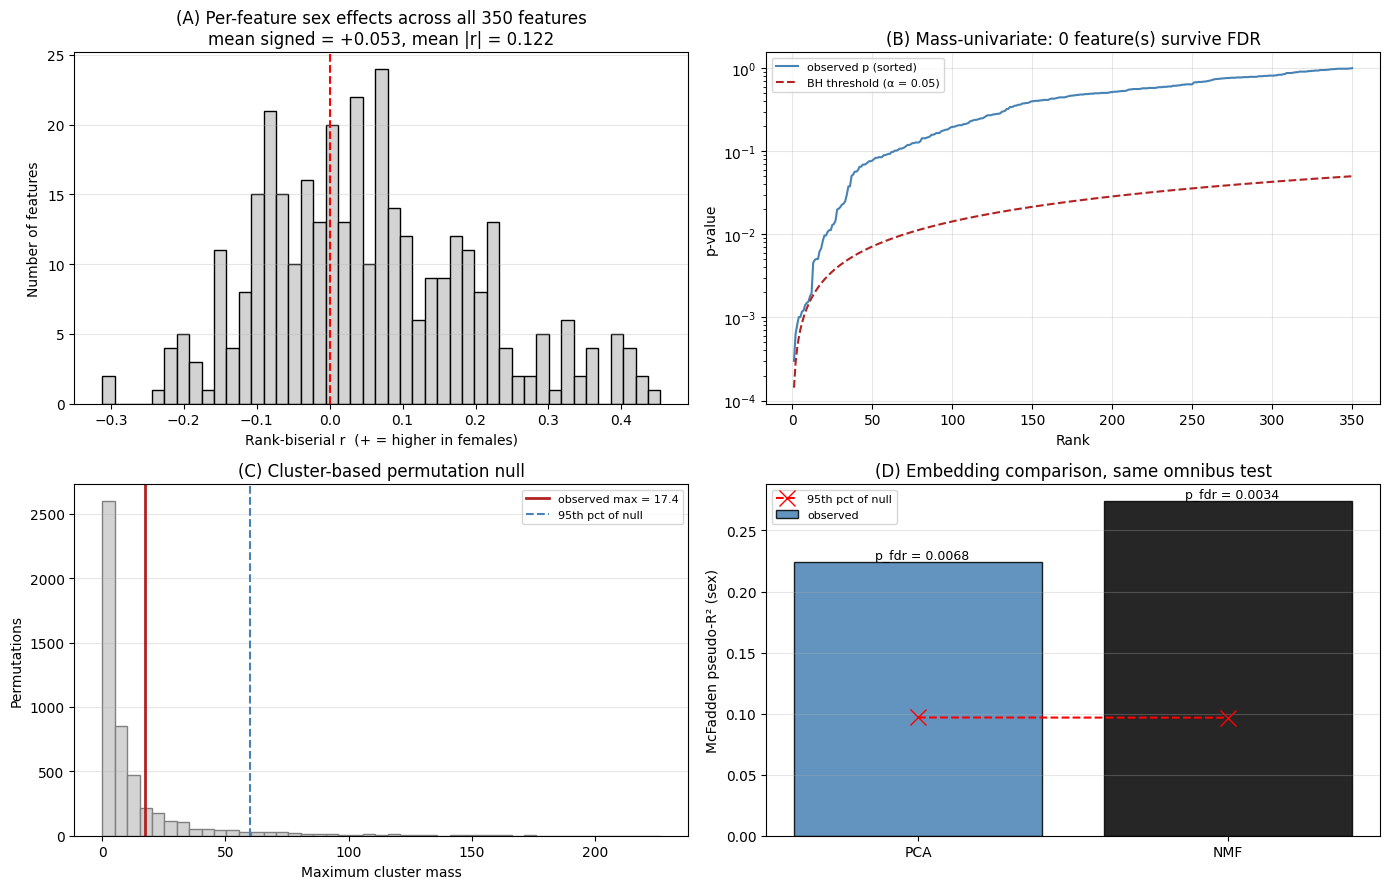

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# (A) univariate effect sizes, signed
ax = axes[0, 0]
ax.hist(uni["rank_biserial"], bins=45, color="lightgray", edgecolor="black")
ax.axvline(0, color="red", linestyle="--")
ax.set_xlabel("Rank-biserial r  (+ = higher in females)")
ax.set_ylabel("Number of features")
ax.set_title(f"(A) Per-feature sex effects across all {len(uni)} features\n"
             f"mean signed = {uni['rank_biserial'].mean():+.3f}, "
             f"mean |r| = {uni['rank_biserial'].abs().mean():.3f}")
ax.grid(alpha=0.3, axis="y")

# (B) univariate p-values vs FDR line
ax = axes[0, 1]
ranks = np.arange(1, len(uni) + 1)
ax.plot(ranks, np.sort(uni["p_raw"].values), color="steelblue", label="observed p (sorted)")
ax.plot(ranks, FDR_ALPHA * ranks / len(uni), color="firebrick", linestyle="--",
        label=f"BH threshold (α = {FDR_ALPHA})")
ax.set_xlabel("Rank"); ax.set_ylabel("p-value")
ax.set_title(f"(B) Mass-univariate: {n_fdr} feature(s) survive FDR")
ax.legend(fontsize=8); ax.grid(alpha=0.3); ax.set_yscale("log")

# (C) cluster permutation null
ax = axes[1, 0]
ax.hist(null_max, bins=45, color="lightgray", edgecolor="gray")
ax.axvline(obs_max, color="firebrick", linewidth=2, label=f"observed max = {obs_max:.1f}")
ax.axvline(np.percentile(null_max, 95), color="steelblue", linestyle="--",
           label="95th pct of null")
ax.set_xlabel("Maximum cluster mass"); ax.set_ylabel("Permutations")
ax.set_title("(C) Cluster-based permutation null")
ax.legend(fontsize=8); ax.grid(alpha=0.3, axis="y")

# (D) omnibus statistic, PCA vs NMF
ax = axes[1, 1]
names = ["PCA", "NMF"]
obs_vals = [pca_sex["observed_stat"], nmf_sex["observed_stat"]]
nulls = [pca_sex["null_95pct"], nmf_sex.get("null_95pct", np.nan)]
xpos = np.arange(2)
ax.bar(xpos, obs_vals, color=["steelblue", "black"], edgecolor="black", alpha=0.85, label="observed")
ax.plot(xpos, nulls, "rx--", markersize=11, label="95th pct of null")
for i, (v, p) in enumerate(zip(obs_vals, [pca_sex["p_fdr"], nmf_sex["p_fdr"]])):
    ax.text(i, v, f"  p_fdr = {p:.3g}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(xpos); ax.set_xticklabels(names)
ax.set_ylabel("McFadden pseudo-R² (sex)")
ax.set_title("(D) Embedding comparison, same omnibus test")
ax.legend(fontsize=8); ax.grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "baselines.png", dpi=150, bbox_inches="tight")
plt.show()

## Verdict

In [10]:
log("\n" + "=" * 78)
log("BASELINE ANALYSES — VERDICT")
log("=" * 78)

if n_fdr == 0 and n_sig_clusters == 0 and bool(nmf_sex["significant_fdr"]):
    log("\n  Neither mass-univariate testing nor cluster-based permutation detects the sex")
    log("  signal that the NMF embedding recovers. This is the strongest available form of")
    log("  the manuscript's central methodological claim, and it is now demonstrated on these")
    log("  data rather than argued from the literature. Report it in Results and cite it in 4.4.")
elif n_fdr > 0 or n_sig_clusters > 0:
    log("\n  A univariate or cluster-based approach also detects the signal. The NMF result is")
    log("  still valid, but the framing that the signal is invisible to conventional analysis")
    log("  cannot stand as written. Sections 4.1 and 4.4 would need adjusting, and the honest")
    log("  version — that NMF localises and characterises a signal simpler methods can also")
    log("  detect — is a weaker but defensible contribution.")
else:
    log("\n  No method detects the signal, including NMF. Check that the inputs to this notebook")
    log("  match the run that produced omnibus_results.csv before drawing any conclusion.")

if bool(pca_sex["significant_fdr"]):
    log("\n  PCA also recovers the sex association through the identical omnibus test. The")
    log("  non-negativity constraint is therefore not what makes the signal detectable — its")
    log("  contribution is interpretability of the components, not sensitivity. Say so plainly")
    log("  in 4.4 rather than letting the current wording imply otherwise.")
else:
    log("\n  PCA does not recover the sex association, while NMF does. The parts-based,")
    log("  non-negative representation is contributing detection sensitivity and not merely")
    log("  interpretability — a specific and defensible methodological claim for 4.4.")

log("\nFiles saved:")
for f in ["baseline_univariate.csv", "baseline_clusters.csv", "baseline_pca_omnibus.csv",
          "baseline_pca_posthoc.csv", "baseline_comparison.csv", "baselines.png",
          "baselines_summary.txt"]:
    log(f"  {f}")
with open(OUTPUT_DIR / "baselines_summary.txt", "w", encoding="utf-8") as fh:
    fh.write("\n".join(report))


BASELINE ANALYSES — VERDICT

  Neither mass-univariate testing nor cluster-based permutation detects the sex
  signal that the NMF embedding recovers. This is the strongest available form of
  the manuscript's central methodological claim, and it is now demonstrated on these
  data rather than argued from the literature. Report it in Results and cite it in 4.4.

  PCA also recovers the sex association through the identical omnibus test. The
  non-negativity constraint is therefore not what makes the signal detectable — its
  contribution is interpretability of the components, not sensitivity. Say so plainly
  in 4.4 rather than letting the current wording imply otherwise.

Files saved:
  baseline_univariate.csv
  baseline_clusters.csv
  baseline_pca_omnibus.csv
  baseline_pca_posthoc.csv
  baseline_comparison.csv
  baselines.png
  baselines_summary.txt
